# Capitolo 10 — Architetture e trasferimento
 **Arcangelo Distante e Cosimo Distante**

 Questo laboratorio verifica metodi con array analitici o dati sintetici. Non usa immagini esterne, pesi preaddestrati o download di dataset. Le attività aperte **N10.A1–N10.A3** chiedono di distinguere ciò che il calcolo dimostra dai limiti dell’esempio.

 ## Avvio e salvataggio
 In Google Colab, aprire il notebook dal repository GitHub attraverso **File → Apri notebook → GitHub**, oppure caricare questo file. Scegliere un runtime CPU: NumPy e Matplotlib sono sufficienti. Eseguire le celle dall’alto verso il basso; per ripartire, riavviare il runtime e rieseguire tutto. In locale usare Jupyter con Python 3, NumPy e Matplotlib. Nessun altro materiale deve essere caricato.

 I risultati sono salvati in `output_capitolo10` nella cartella di lavoro. Al termine scaricare la cartella degli output e salvare una copia del notebook eseguito. In Colab i file del runtime sono temporanei. Un’esecuzione locale non documenta automaticamente una prova svolta nel servizio Colab.


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
OUTPUT = Path("output_capitolo10")
OUTPUT.mkdir(exist_ok=True)
risultati = {"capitolo": 10, "natura": "esempi analitici e sintetici", "dispositivo": "CPU"}
def mostra(a):
    return np.array2string(np.asarray(a), precision=6, separator=", ")


## N10.A1 — Patch embedding e ordine
Una matrice assegnata seleziona due valori della patch e somma gli altri due. Non è un embedding appreso. **Domande:** quale ordine delle componenti viene usato? Perché la stessa proiezione si applica a ogni patch? Quale informazione può andare persa con una proiezione da quattro a tre dimensioni?


In [2]:
image=np.arange(16).reshape(4,4)
patches=image.reshape(2,2,2,2).transpose(0,2,1,3).reshape(4,4)
E=np.array([[1.,0.,0.],[0.,1.,0.],[0.,0.,1.],[0.,0.,1.]])
b=np.array([.1,.2,.3]);tokens=patches@E+b
print("Patch:",mostra(patches),"Token:",mostra(tokens),sep="\n")
assert np.allclose(tokens[0],[.1,1.2,9.3])
risultati["patch"]={"patch":patches.tolist(),"token":tokens.tolist(),"parametri_proiezione":int(E.size+b.size)}


Patch:
[[ 0,  1,  4,  5],
 [ 2,  3,  6,  7],
 [ 8,  9, 12, 13],
 [10, 11, 14, 15]]
Token:
[[ 0.1,  1.2,  9.3],
 [ 2.1,  3.2, 13.3],
 [ 8.1,  9.2, 25.3],
 [10.1, 11.2, 29.3]]


## N10.A2 — Tre token in self-attention
Le matrici Q, K e V sono assegnate per controllare ogni operazione. Nessuna cella usa un transformer preaddestrato o produce una spiegazione di un’immagine reale. **Domande:** perché le righe di A sommano a uno? Un peso Aij alto dimostra un contributo positivo alla classe corretta? Che cosa succede riordinando coerentemente i token in assenza di posizioni?


A:
[[0.401112, 0.197776, 0.401112],
 [0.197776, 0.401112, 0.401112],
 [0.248255, 0.248255, 0.50349 ]]
Output:
[[1.604448, 0.796664],
 [1.401112, 1.203336],
 [1.758725, 1.      ]]


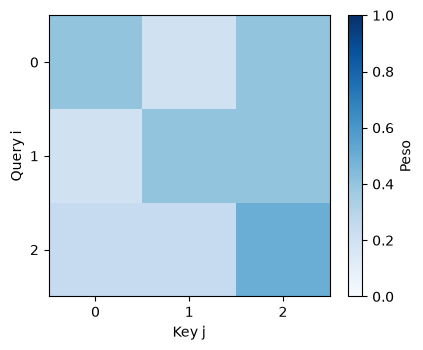

In [3]:
Q=np.array([[1.,0.],[0.,1.],[1.,1.]])
K=Q.copy();V=np.array([[1.,0.],[0.,2.],[3.,1.]])
def attention(Q,K,V):
    score=Q@K.T/np.sqrt(Q.shape[1]);weights=np.exp(score-score.max(axis=1,keepdims=True));weights/=weights.sum(axis=1,keepdims=True)
    return weights,weights@V
A,O=attention(Q,K,V);perm=np.array([2,0,1]);Ap,Op=attention(Q[perm],K[perm],V[perm])
assert np.allclose(A.sum(axis=1),1) and np.allclose(Op,O[perm])
print("A:",mostra(A),"Output:",mostra(O),sep="\n")
fig,ax=plt.subplots(figsize=(4.5,3.6));im=ax.imshow(A,vmin=0,vmax=1,cmap="Blues");ax.set(xlabel="Key j",ylabel="Query i",xticks=range(3),yticks=range(3));fig.colorbar(im,ax=ax,label="Peso");fig.tight_layout();fig.savefig(OUTPUT/"attenzione.png",dpi=160);plt.show()
np.savetxt(OUTPUT/"attenzione.csv",A,delimiter=",")
risultati["attenzione"]={"pesi":A.tolist(),"output":O.tolist(),"equivarianza_permutazione":bool(np.allclose(Op,O[perm]))}


## N10.A3 — Dove passa il gradiente
Una trasformazione lineare 2×2 rappresenta un backbone minimo; un’altra matrice produce due score. Confrontiamo un singolo aggiornamento della testa con un aggiornamento di testa e backbone. Non simuliamo un risultato di trasferimento fra dataset: il modello serve soltanto a isolare la regola della catena. **Domande:** quali parametri e quali gradienti servono nel linear probe? Perché calcolare il suffisso trainabile senza registrare il grafo impedirebbe il suo adattamento? Una diminuzione su questo unico esempio prova una migliore generalizzazione del fine-tuning?


In [4]:
x=np.array([1.,2.]);B=np.eye(2);W=np.array([[1.,-1.],[-1.,1.]])
def loss_grads(B,W):
    h=B@x;s=W@h;p=np.exp(s-s.max());p/=p.sum();g=p.copy();g[0]-=1
    return -np.log(p[0]),np.outer(g,h),np.outer(W.T@g,x)
before,gW,gB=loss_grads(B,W);eta=.05
Wlp=W-eta*gW;Blp=B.copy();Wft=W-eta*gW;Bft=B-eta*gB
lp=loss_grads(Blp,Wlp)[0];ft=loss_grads(Bft,Wft)[0]
print("Loss prima:",before,"dopo LP:",lp,"dopo FT:",ft)
print("Gradiente backbone:",mostra(gB),"Backbone LP:",mostra(Blp),"Backbone FT:",mostra(Bft),sep="\n")
assert np.array_equal(Blp,B) and not np.array_equal(Bft,B)
risultati["trasferimento_minimo"]={"loss_prima":float(before),"loss_dopo_lp":float(lp),"loss_dopo_ft":float(ft),"gradiente_backbone":gB.tolist(),"backbone_lp":Blp.tolist(),"backbone_ft":Bft.tolist(),"limite":"Un esempio analitico: nessuna conclusione sulla generalizzazione o sul trasferimento reale."}


Loss prima: 2.1269280110429727 dopo LP: 1.7504034861907787 dopo FT: 0.6148716148493747
Gradiente backbone:
[[-1.761594, -3.523188],
 [ 1.761594,  3.523188]]
Backbone LP:
[[1., 0.],
 [0., 1.]]
Backbone FT:
[[ 1.08808 ,  0.176159],
 [-0.08808 ,  0.823841]]


In [5]:
with (OUTPUT / "risultati_capitolo10.json").open("w", encoding="utf-8") as f:
    json.dump(risultati, f, indent=2, ensure_ascii=False, allow_nan=False)
print("Risultati salvati in", OUTPUT)


Risultati salvati in output_capitolo10
